In [1]:
#!pip install imblearn

In [2]:
import pandas as pd

import numpy as np

from sklearn.preprocessing import LabelEncoder

from imblearn.over_sampling import SMOTE,RandomOverSampler

from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV,KFold

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

from sklearn.tree import DecisionTreeClassifier 

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import SVC

from sklearn.ensemble import RandomForestClassifier , AdaBoostClassifier,GradientBoostingClassifier

import xgboost 

from xgboost import XGBClassifier


In [3]:
df = pd.read_csv("Bank data.csv")

In [4]:
df.head()

,Cust No.,First Name,Surname,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
0,1,Walter,Hargrave,619,France,Female,42,2.0,NaN,1.0,Yes,Yes,101349,1
1,2,Daniel,Hill,608,Spain,Female,41,1.0,83807.86,1.0,No,Yes,112543,0
2,3,Melissa,Onio,502,France,Female,42,8.0,159660.80,3.0,Yes,No,113932,1
3,4,Miley,Boni,699,France,Female,39,1.0,NaN,2.0,No,No,93827,0
4,5,James,Mitchell,850,Spain,Female,43,2.0,125510.82,1.0,Yes,Yes,79084,0


In [5]:
df["Exited"].value_counts()

0    8009
1    2062
Name: Exited, dtype: int64

In [6]:
df.shape

(10071, 14)

In [7]:
df.dropna(inplace=True)

In [8]:
df.shape

(6270, 14)

In [9]:
df.drop("Cust No.",axis = 1,inplace=True)
df.drop("First Name",axis = 1,inplace=True)
df.drop("Surname",axis = 1,inplace=True)

In [10]:
df.head()

,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
1,608,Spain,Female,41,1.0,83807.86,1.0,No,Yes,112543,0
2,502,France,Female,42,8.0,159660.80,3.0,Yes,No,113932,1
4,850,Spain,Female,43,2.0,125510.82,1.0,Yes,Yes,79084,0
5,645,Spain,Male,44,8.0,113755.78,2.0,Yes,No,149757,1
7,376,Germany,Female,29,4.0,115046.74,4.0,Yes,No,119347,1


In [11]:
le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == "O":
        df[col] = le.fit_transform(df[col])

In [12]:
df.head()

,Credit Score,Geography,Gender,Age,Tenure,Balance,Num Of Policies,Credit Card,Active Member,Salary,Exited
1,608,2,0,41,1.0,83807.86,1.0,0,1,112543,0
2,502,0,0,42,8.0,159660.80,3.0,1,0,113932,1
4,850,2,0,43,2.0,125510.82,1.0,1,1,79084,0
5,645,2,1,44,8.0,113755.78,2.0,1,0,149757,1
7,376,1,0,29,4.0,115046.74,4.0,1,0,119347,1


In [13]:
df.shape

(6270, 11)

In [14]:
x = df.drop("Exited",axis = 1)
y = df[["Exited"]]

In [15]:
exited_count = y.value_counts()

In [16]:
y.value_counts()

Exited
0         4738
1         1532
dtype: int64

<AxesSubplot:ylabel='None'>

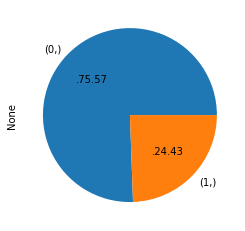

In [17]:
y.value_counts().plot.pie(autopct = '.%.2f')

([<matplotlib.patches.Wedge at 0x24056514bb0>,
 [Text(-0.7915290347188769, 0.7638597955102776, '(0,)'),
  Text(0.7915291062365891, -0.7638597214019774, '(1,)')],
 [Text(-0.43174310984666014, 0.41665079755106044, '75.57'),
  Text(0.4317431488563213, -0.41665075712835126, '24.43')])

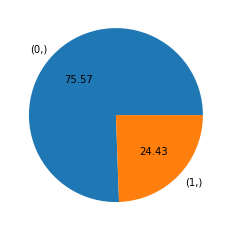

In [18]:
f,ax = plt.subplots()
ax.pie(y.value_counts(),autopct='%.2f',labels=exited_count.index)

### Using Random Sampler

In [19]:
rd = RandomOverSampler()

In [20]:
rd_x,rd_y = rd.fit_resample(x,y)

In [21]:
rd_x.shape

(9476, 10)

In [22]:
rd_y.shape

(9476, 1)

(      Credit Score  Geography  Gender  Age  Tenure    Balance  \
 0              608          2       0   41     1.0   83807.86   
 1              502          0       0   42     8.0  159660.80   
 2              850          2       0   43     2.0  125510.82   
 3              645          2       1   44     8.0  113755.78   
 4              376          1       0   29     4.0  115046.74   
 ...            ...        ...     ...  ...     ...        ...   
 9471           358          2       0   52     8.0  143542.36   
 9472           507          1       1   36     9.0  118214.32   
 9473           404          1       0   54     4.0  125456.07   
 9474           681          1       1   42     3.0  118199.97   
 9475           616          1       0   45     6.0  128352.59   
 
       Num Of Policies  Credit Card  Active Member  Salary  
 0                 1.0            0              1  112543  
 1                 3.0            1              0  113932  
 2                 1.0 

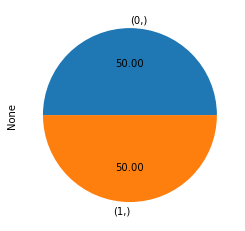

In [23]:
rd_x,rd_y.value_counts().plot.pie(autopct = '%.2f')

### Using SMOTE

In [24]:
sm  = SMOTE()

In [25]:
sm_x,sm_y  = sm.fit_resample(x,y)

In [26]:
sm_x.shape

(9476, 10)

(      Credit Score  Geography  Gender  Age    Tenure        Balance  \
 0              608          2       0   41  1.000000   83807.860000   
 1              502          0       0   42  8.000000  159660.800000   
 2              850          2       0   43  2.000000  125510.820000   
 3              645          2       1   44  8.000000  113755.780000   
 4              376          1       0   29  4.000000  115046.740000   
 ...            ...        ...     ...  ...       ...            ...   
 9471           737          0       0   42  2.432211   87718.412648   
 9472           548          1       0   35  7.128231  127335.440898   
 9473           607          1       1   40  9.100690  132557.737335   
 9474           640          0       0   39  6.160043  131578.104856   
 9475           777          1       0   57  6.863141  150769.993834   
 
       Num Of Policies  Credit Card  Active Member  Salary  
 0            1.000000            0              1  112543  
 1          

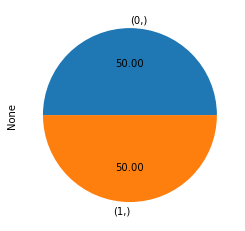

In [27]:
sm_x,sm_y.value_counts().plot.pie(autopct = "%.2f")

### Model Building with Random Sampled balanced class

In [28]:
x_train,x_test,y_train,y_test =train_test_split(rd_x,rd_y,test_size=0.3,random_state=100)

In [29]:
lo = LogisticRegression()

In [30]:
lo.fit(x_train,y_train)

LogisticRegression()

In [31]:
y_pred = lo.predict(x_test)

In [32]:
accuracy_score(y_test,y_pred)

0.6644389729159339

In [33]:
kf = KFold(n_splits=10,shuffle=True)
cv = cross_val_score(lo,rd_x,rd_y,cv = kf)

In [34]:
cv.mean()

0.6692673733174715

### Model Building with SMOTE balanced class

In [35]:
x_train,x_test,y_train,y_test =train_test_split(sm_x,sm_y,test_size=0.3)

In [36]:
lo.fit(x_train,y_train)

LogisticRegression()

In [37]:
y_pred = lo.predict(x_test)

In [38]:
accuracy_score(y_test,y_pred)

0.6781568765388674

In [39]:
kf = KFold(n_splits=10,shuffle=True)
cv = cross_val_score(lo,rd_x,rd_y,cv = kf)

In [40]:
cv.mean()

0.6662096382536011

### Function for Model Building

In [41]:
# Function for train_test_split

def train_and_test_split(x,y,test_size = 0.3,random_state = 100):
    
    return  train_test_split(x,y,test_size = test_size,random_state = random_state)


In [42]:
def build_model(model,model_name,x,y):
    
    x_train,x_test,y_train,y_test = train_and_test_split(x,y)
    
    model.fit(x_train,y_train)
    
    y_pred = model.predict(x_test)
    
    accuracy = accuracy_score(y_test,y_pred)
        
    temp = [model_name,accuracy]
    
    return temp

In [43]:
build_model(KNeighborsClassifier(),"Logistic",rd_x,rd_y)

['Logistic', 0.6394653534998241]

In [46]:
def build_multiple_models(x,y):
    
    col_names = ["Model_Name" , "R2 Score" ,"RMSE"]
    
    result_df  = pd.DataFrame(columns = col_names)
    
    result_df.loc[len(result_df)] = build_model(LogisticRegression(),"Logistic Regression",x,y)
    result_df.loc[len(result_df)] = build_model(DecisionTreeClassifier(),"Decision Tree Classifier",x,y)
    result_df.loc[len(result_df)] = build_model(KNeighborsClassifier(),"KNN Classifier",x,y)
    result_df.loc[len(result_df)] = build_model(SVC(),"Support Vector Classifier",x,y)
    result_df.loc[len(result_df)] = build_model(RandomForestClassifier(),"Random Forest Classifier",x,y)
    result_df.loc[len(result_df)] = build_model(AdaBoostClassifier(),"AdaBoost Classifier",x,y)
    result_df.loc[len(result_df)] = build_model(GradientBoostingClassifier(),"GBoost Classifier",x,y)
    result_df.loc[len(result_df)] = build_model(XGBClassifier(),"XGBoost Classifier",x,y)

    
    
    return result_df.sort_values("R2 Score" ,ascending=False)

In [47]:
build_multiple_models(rd_x,rd_y)

ValueError: cannot set a row with mismatched columns